# Harmonic events from EEG
**CS1090A · Group 18 · Milestone 2: data wrangling and project redefinition**

**Group members:** Davis Bone, Rose Friedman, Ana Maria Ramirez Diaz, Trent Rogers, Payton Shen

**Repository:** https://github.com/davisbone/Harmonic-EEG

**Question:** Can 21 early EEG voltage features tell standard from deviant middle chords in participants the model was not trained on?

This notebook loads the processed event table that ships with the repository, explains what one row means, shows what cleaning removed and why, and states the question for the next milestone. It does not fit a classifier yet. Start Jupyter from the repository root after `uv sync`.

The [visual walkthrough](docs/explainer.html) explains the experiment and processing with pictures (download it and open it in a browser). The [methods](docs/methods.md) list every processing choice and its limits.

**Use of generative AI.** The processing pipeline (`eeg_pipeline/`), the tests, this notebook, the methods document, and the visual walkthrough were written with OpenAI Codex (GPT-6 Astra). An earlier prototype built with Anthropic's Claude Code (Claude Opus 5.5) was used as a reference. Claude Code was also used to review the work and to edit this notebook and the README.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from eeg_pipeline.config import PREDICTORS, ROIS, WINDOWS

ROOT = Path.cwd()
RESULTS = ROOT / "results"
provenance = json.loads((RESULTS / "provenance.json").read_text())

events = pd.read_parquet(RESULTS / "events.parquet")
ledger = pd.read_csv(RESULTS / "event_ledger.csv.gz", keep_default_na=False)
audit = pd.read_csv(RESULTS / "participant_audit.csv")
plt.rcParams.update({"figure.figsize": (9, 3.5), "axes.spines.top": False, "axes.spines.right": False})
print(f"Loaded {len(events):,} events, {events.subject.nunique()} participants, {len(PREDICTORS)} EEG predictors.")

Loaded 32,935 events, 27 participants, 21 EEG predictors.


## 1. Getting the data

The source is [NEMAR on003570](https://www.nemar.org/dataset/on003570), version 1.0.0, mirroring OpenNeuro ds003570. The deposited experiment contains 40 participants and 64 EEG channels sampled at 2,048 Hz. Each trial is three chords about 400 ms apart. The middle chord is either a **standard** (the expected chord) or a **deviant**. An *exemplar deviant* keeps the same chord but rearranges its notes (a different inversion). A *function deviant* swaps in a chord with a different harmonic role. Participants were asked to press a button when they heard a deviant. The binary target combines the two deviant types.

Ten of the 40 recordings in the release are cut off upstream (less than half of the EEG is present), so they are excluded. Two more (`sub-001` and `sub-030`) are about 92% complete; their usable part is kept.

In [2]:
sizes = pd.Series({
    "Pinned release (decimal GB)": provenance["full_release_bytes"] / 1e9,
    "Pinned release (GiB)": provenance["full_release_bytes"] / 2**30,
    "Included event table (MB)": (RESULTS / "events.parquet").stat().st_size / 1e6,
}, name="size")
display(sizes.to_frame().round(2))
display(audit.groupby("source_status", sort=False).agg(participants=("subject", "size")))

,size
Pinned release (decimal GB),38.78
Pinned release (GiB),36.12
Included event table (MB),7.38


,participants
source_status,
verified_prefix,2
complete,28
severely_truncated,10


### Optional: reproduce the raw-to-table calculation

The ordinary notebook run does not download tens of gigabytes or rerun ICA. To rebuild, first install the additional tools with `uv sync --extra preprocessing`. Set `REBUILD_FROM_RAW` to `True` only when you intend to download and process the full release. Use an existing downloaded directory if available.

A full rebuild takes hours. It processes one participant at a time, so an interrupted build can be restarted without redoing finished participants.

In [3]:
REBUILD_FROM_RAW = False
DATA_DIR = ROOT / "Data" / "on003570"

if REBUILD_FROM_RAW:
    from eeg_pipeline.source import download
    from eeg_pipeline.build import build
    download(DATA_DIR)
    build(DATA_DIR, RESULTS)
    print("Rebuild finished. Restart and run this notebook again to load the new results.")

## 2. Understanding a row

**One row is one retained middle-chord event from one participant.** The 21 EEG predictors are measured in microvolts. Each is the average over one scalp region and one time window, relative to that event's preceding baseline.

An **ERP** (event-related potential) is the small voltage change the brain produces in response to an event, measured at the scalp and lined up in time with that event. Each predictor is a mean ERP voltage. For example, `erp_Cmid_150_250_uv` is the average voltage over the six central-midline electrodes from 150 to 250 ms after the middle chord, in microvolts (µV).

| Region code | Scalp area | Electrodes |
|---|---|---|
| `Lfront` | Left frontal | AF3, F3, F5, F7, FC3, FC5 |
| `Rfront` | Right frontal | AF4, F4, F6, F8, FC4, FC6 |
| `FCmid` | Frontal-central midline | Fz, F1, F2, FC1, FCz, FC2 |
| `Cmid` | Central midline | C1, Cz, C2, CP1, CPz, CP2 |
| `Pmid` | Parietal midline | P1, Pz, P2, PO3, POz, PO4 |
| `Ltemp` | Left temporal | T7, TP7, P7, P9 |
| `Rtemp` | Right temporal | T8, TP8, P8, P10 |

The three time windows are 80–150, 150–250, and 250–400 ms after the middle chord.

| Column family | Meaning | Modeling role |
|---|---|---|
| `erp_*_uv` | Seven scalp regions × three early time windows | The only permitted predictors |
| `target` | 0 = standard; 1 = either deviant subtype | Binary outcome |
| `condition` | Standard, function deviant, or exemplar deviant | Outcome detail; never a predictor |
| `subject` | Participant ID | Grouping for validation, never a predictor |
| `event_id`, `trial`, `block`, `onset_s` | Event identity and timing | Audit metadata, never predictors |
| `source_available` | Required samples exist in the original recording | Audit metadata |
| `group` | `Cl` = classical, `Imp` = improvising musician | Descriptive metadata |

The ID and timing columns would leak the label; see *Information leakage* below.

In [4]:
display(events.head())
print("Table shape:", events.shape)
display(events.dtypes.astype(str).rename("dtype").to_frame())
display(events.describe().T[["count", "mean", "std", "min", "max"]].round(3))
display(events.target.value_counts().rename("events").to_frame())
print(f"Deviant share: {events.target.mean():.1%}. Always guessing standard would be {1 - events.target.mean():.1%} accurate.")

,subject,trial,event_id,block,onset_s,condition,target,source_available,erp_Lfront_080_150_uv,erp_Lfront_150_250_uv,...,erp_Pmid_080_150_uv,erp_Pmid_150_250_uv,erp_Pmid_250_400_uv,erp_Ltemp_080_150_uv,erp_Ltemp_150_250_uv,erp_Ltemp_250_400_uv,erp_Rtemp_080_150_uv,erp_Rtemp_150_250_uv,erp_Rtemp_250_400_uv,group
0,sub-001,12,sub-001_trial-0012,1,21.140137,standard,0,True,-7.683005,-4.475911,...,10.962259,9.908422,6.281861,9.964424,5.417424,2.860510,3.667793,-4.211687,-3.682085,Cl
1,sub-001,13,sub-001_trial-0013,1,22.739746,standard,0,True,-9.713874,-10.230387,...,7.846989,9.071742,10.685245,5.098308,2.847263,-1.191390,9.847172,8.353021,10.835022,Cl
2,sub-001,14,sub-001_trial-0014,1,24.346191,standard,0,True,5.555457,4.078070,...,-5.138405,-5.918432,-1.350917,-2.626311,-3.194741,-5.064069,-0.351945,-4.007674,-6.119110,Cl
3,sub-001,15,sub-001_trial-0015,1,25.940430,standard,0,True,2.965287,4.661370,...,-3.966921,-5.608922,-2.380754,7.052797,1.664525,1.609157,3.351040,-2.921806,1.408856,Cl
4,sub-001,16,sub-001_trial-0016,1,27.538086,standard,0,True,-2.523194,2.249280,...,1.187517,-6.144309,2.128830,2.096683,0.160742,-1.100486,4.671220,-2.593057,1.613290,Cl


Table shape: (32935, 30)


,dtype
subject,str
trial,int64
event_id,str
block,int64
onset_s,float64
condition,str
target,int64
source_available,bool
erp_Lfront_080_150_uv,float64
erp_Lfront_150_250_uv,float64


,count,mean,std,min,max
trial,32935.0,715.010,413.562,10.000,1440.000
block,32935.0,4.471,2.285,1.000,8.000
onset_s,32935.0,1167.385,675.816,21.114,2475.187
target,32935.0,0.160,0.367,0.000,1.000
erp_Lfront_080_150_uv,32935.0,-0.606,3.856,-27.619,23.132
erp_Lfront_150_250_uv,32935.0,-0.486,4.216,-34.026,26.594
erp_Lfront_250_400_uv,32935.0,-0.510,4.782,-34.385,33.225
erp_Rfront_080_150_uv,32935.0,-0.718,3.990,-25.236,36.015
erp_Rfront_150_250_uv,32935.0,-0.593,4.401,-35.864,40.912
erp_Rfront_250_400_uv,32935.0,-0.599,4.966,-39.293,47.876


,events
target,
0,27663
1,5272


Deviant share: 16.0%. Always guessing standard would be 84.0% accurate.


## 3. Cleaning and preprocessing

The processing code treats unavailable data, block boundaries, bad electrodes, artifacts, and noisy events as separate problems. The thresholds are fixed rules that never use the labels; they reduce artifacts but cannot guarantee that every remaining epoch is clean.

1. Check the source files and event timing. Keep the usable part of the two partly complete recordings; never invent missing samples.
2. Resample to 256 Hz and filter each recording block separately. A **high-pass filter** removes slow drift, a **notch filter** removes 60 Hz power-line hum, and a 40 Hz **low-pass filter** removes fast noise. Filters need signal on both sides of each point, so events within about 21 seconds of a block edge are skipped; most of that margin comes from the very slow 0.1 Hz high-pass filter.
3. Find electrodes that are bad for much of the recording, rebuild them from neighboring electrodes (**interpolation**), and switch to the **average reference** (subtract the mean of all electrodes at each moment, so voltages do not depend on one reference electrode).
4. Remove artifacts with **ICA** (independent component analysis). Like PCA, ICA rewrites the 64 channels as a set of components. PCA picks components that capture the most variance; ICA picks components that are statistically independent, which tends to separate eye blinks, muscle activity, and heartbeats from brain activity. An automatic classifier (ICLabel) labels each component, and components labeled as artifacts with probability above 0.8 are removed.
5. Repair electrodes that are noisy only now and then, then check all 64 channels over each **epoch** (the 500 ms slice from 100 ms before to 400 ms after the middle chord).
6. Exclude participants with too many bad electrodes or too few clean epochs (thresholds below).
7. Subtract each channel's mean over the 100 ms before the middle chord (the **baseline**), then average into the 21 predictors.

**Why 27 of 40 participants:** 40 recorded − 10 recordings cut off upstream − 3 participants with more than six bad electrodes (`sub-006`: 7, `sub-023`: 9, `sub-035`: 13) = **27**.

| Rule | Threshold | Reason |
|---|---|---|
| Bad electrodes per participant | at most 6 of 64 | The average reference and ICA use every electrode, so many rebuilt electrodes weaken the cleaning everywhere, even when the bad ones lie outside the feature regions (as for `sub-023`) |
| Epoch amplitude | every channel's peak-to-peak range below 150 µV | Larger swings are almost always movement or electrode artifacts |
| Flat channel | every channel's peak-to-peak range at least 1 µV | A flat channel means a disconnected electrode |
| Clean epochs per participant | at least 60% of eligible epochs | A participant below this is mostly noise |
| ICA artifact removal | ICLabel probability above 0.8 | Remove only confident artifact labels, to avoid removing brain signal |
| Block-edge margin | about 21 s | Filter edge effects (step 2) |

The [methods](docs/methods.md) give the exact settings and the reasons for each exclusion.

,events
Candidate events,57600
Signal exists,42978
Clear of block/filter edges,37477
Pass event signal checks,32935
Final table,32935


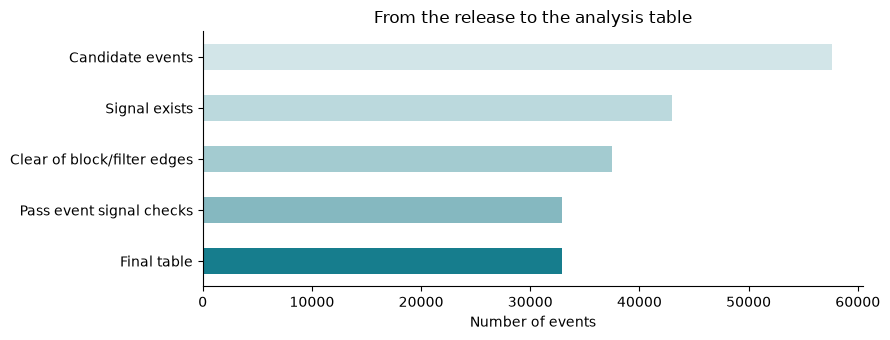

,excluded_events
reason,
filter_edge_guard,5501
participant:too_many_bad_channels,3772
signal:amplitude,770
source_severely_truncated,14400
source_unavailable,222


,subject,source_status,n_source_available,n_edge_eligible,n_signal_pass,n_included,participant_reason
0,sub-001,verified_prefix,1327,1143,1137,1137,NaN
1,sub-002,complete,1440,1288,1265,1265,NaN
2,sub-003,severely_truncated,0,0,0,0,source_severely_truncated
3,sub-004,severely_truncated,0,0,0,0,source_severely_truncated
4,sub-005,severely_truncated,0,0,0,0,source_severely_truncated
5,sub-006,complete,1440,1256,0,0,too_many_bad_channels
6,sub-007,severely_truncated,0,0,0,0,source_severely_truncated
7,sub-008,complete,1440,1252,1249,1249,NaN
8,sub-009,complete,1440,1255,1205,1205,NaN
9,sub-010,severely_truncated,0,0,0,0,source_severely_truncated


In [5]:
flow = pd.Series({
    "Candidate events": len(ledger),
    "Signal exists": int(ledger.source_available.sum()),
    "Clear of block/filter edges": int(ledger.boundary_eligible.sum()),
    "Pass event signal checks": int(ledger.signal_pass.sum()),
    "Final table": int(ledger.included.sum()),
}, name="events")
display(flow.to_frame())
ax = flow.iloc[::-1].plot.barh(color=["#167d8d", "#85b8c0", "#a3cbd0", "#bbd9dd", "#d2e5e8"])
ax.set(title="From the release to the analysis table", xlabel="Number of events", ylabel="")
plt.tight_layout(); plt.show()
display(ledger.loc[~ledger.included].groupby("reason").size().rename("excluded_events").to_frame())
display(audit[["subject", "source_status", "n_source_available", "n_edge_eligible", "n_signal_pass", "n_included", "participant_reason"]])

### Missingness, unusual values, and unequal classes

Missing EEG is not imputed. Source gaps and rejected epochs remain represented in the ledger, so an absent row in the final table is an explicit exclusion rather than a hidden missing value. Interpolation repairs an electrode from neighboring electrodes; it does not recover missing portions of a recording.

The final EEG features must be finite. Large but valid feature values should not be dropped merely because they are unusual; artifact decisions are made from the signal and fixed QC rules. Feature ranges are shown below because future regularized models require scaling inside training folds.

Standards are much more frequent than deviants. Exclusion rates are reported by condition so class-dependent losses are visible; class counts are not used to choose the cleaning thresholds.

,missing
subject,0
trial,0
event_id,0
block,0
onset_s,0
condition,0
target,0
source_available,0
erp_Lfront_080_150_uv,0
erp_Lfront_150_250_uv,0


,candidates,source_available,boundary_eligible,included,retained_fraction_of_candidates,retained_fraction_of_edge_eligible,fraction_of_final_table
condition,,,,,,,
exemplar_dev,4360,3250,3011,2657,0.609,0.882,0.081
function_dev,4440,3318,2967,2615,0.589,0.881,0.079
standard,48800,36410,31499,27663,0.567,0.878,0.840


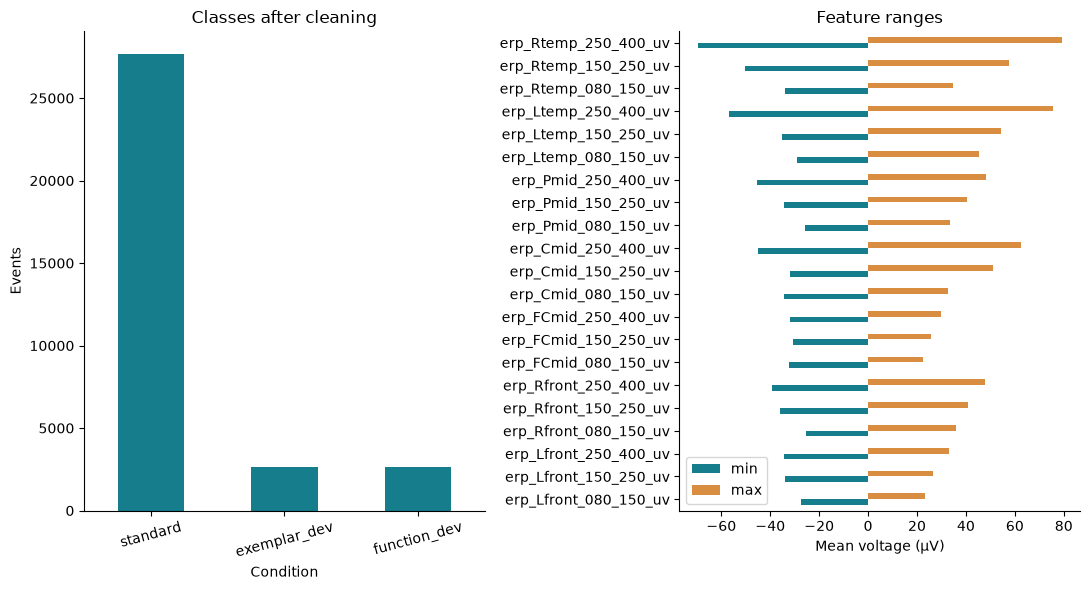

In [6]:
display(events.isna().sum().rename("missing").to_frame())
class_audit = ledger.groupby("condition").agg(
    candidates=("event_id", "size"), source_available=("source_available", "sum"),
    boundary_eligible=("boundary_eligible", "sum"), included=("included", "sum"))
class_audit["retained_fraction_of_candidates"] = class_audit.included / class_audit.candidates
class_audit["retained_fraction_of_edge_eligible"] = class_audit.included / class_audit.boundary_eligible
class_audit["fraction_of_final_table"] = class_audit.included / len(events)
display(class_audit.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
events.condition.value_counts().plot.bar(ax=axes[0], color="#167d8d", rot=15)
axes[0].set(title="Classes after cleaning", ylabel="Events", xlabel="Condition")
events[PREDICTORS].agg(["min", "max"]).T.plot.barh(ax=axes[1], color=["#167d8d", "#d88d40"])
axes[1].set(title="Feature ranges", xlabel="Mean voltage (µV)", ylabel="")
fig.set_size_inches(11, 6); plt.tight_layout(); plt.show()

### Information leakage

A column leaks if it carries information about the label that a genuine prediction could not use.

- `condition` and `target` are the label itself.
- `trial`, `block`, `onset_s`, and `event_id` give the label away. Every participant heard the same sequence, so the trial number alone identifies the deviants (checked below). Holding out whole participants does not fix this, so these columns are never predictors.
- Within every block, the first nine trials are always standards.
- The cleaning rules never look at the label. The share of epochs rejected for amplitude is about the same in each condition (below).
- Scaling and any other fitted step will be learned on the training folds only.
- Participants pressed a button for deviants, and some presses come before 400 ms. The latest window (250–400 ms) may therefore partly reflect movement preparation, not hearing alone.

In [7]:
in_order = ledger.sort_values(["subject", "trial"])
position = in_order.groupby(["subject", "block"]).cumcount() + 1
print("Same condition at each trial number for every participant:", in_order.groupby("trial").condition.nunique().max() == 1)
print("Trials 1-9 of every block are standards:", (in_order.condition[position <= 9] == "standard").all())

checked = ledger[ledger.boundary_eligible & (ledger.reason != "participant:too_many_bad_channels")]
rejected = (checked.reason == "signal:amplitude").groupby(checked.condition).mean()
display(rejected.rename("share rejected for amplitude").to_frame().round(3))

Same condition at each trial number for every participant: True
Trials 1-9 of every block are standards: True


,share rejected for amplitude
condition,
exemplar_dev,0.019
function_dev,0.021
standard,0.023


### One event becomes one table row

The example below is an actual retained event. The baseline interval is during the first chord, not a silent rest period. Shaded windows identify the three averages. The signal has already been filtered and artifact-corrected; the diagram is not an unprocessed recording.

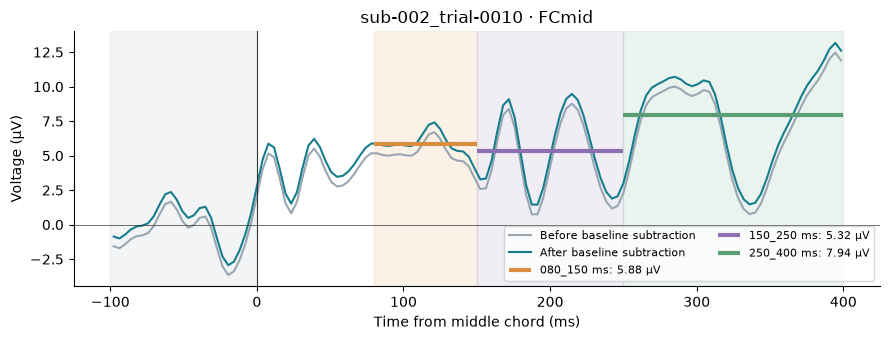

,table value (µV)
erp_FCmid_080_150_uv,5.877933
erp_FCmid_150_250_uv,5.31636
erp_FCmid_250_400_uv,7.940117


In [8]:
with np.load(RESULTS / "example.npz") as saved:
    example = {name: saved[name] for name in saved.files}
index = int(np.flatnonzero(example["included"])[0])
region = "FCmid"
channels = list(example["channel_names"])
indices = [channels.index(name) for name in ROIS[region]]
time_ms = example["times_s"] * 1000
before_baseline = example["clean_uv"][index, indices].mean(axis=0)
corrected = example["baseline_corrected_uv"][index, indices].mean(axis=0)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(time_ms, before_baseline, color="#99a7b2", label="Before baseline subtraction")
ax.plot(time_ms, corrected, color="#167d8d", label="After baseline subtraction")
ax.axvspan(-100, 0, color="#99a7b2", alpha=.12)
for (window, (start, stop)), color in zip(WINDOWS.items(), ["#d88d40", "#8d70b1", "#5b9e76"]):
    mask = (example["times_s"] >= start) & (example["times_s"] < stop)
    mean = corrected[mask].mean()
    ax.axvspan(start * 1000, stop * 1000, color=color, alpha=.12)
    ax.hlines(mean, start * 1000, stop * 1000, color=color, lw=3, label=f"{window} ms: {mean:.2f} µV")
ax.axvline(0, color="#333", lw=.8); ax.axhline(0, color="#333", lw=.5)
ax.set(title=f"{example['event_ids'][index]} · {region}", xlabel="Time from middle chord (ms)", ylabel="Voltage (µV)")
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()
row = events.set_index("event_id").loc[str(example["event_ids"][index])]
display(row[[name for name in PREDICTORS if name.startswith(f"erp_{region}_")]].to_frame("table value (µV)"))

## 4. Refined question and next analysis

**Question:** Can 21 early EEG voltage features tell standard from deviant middle chords in participants the model was not trained on?

**How we will know:** the answer is *yes* if a model evaluated with participant-grouped cross-validation reaches a held-out ROC AUC above 0.5, with a bootstrap confidence interval over held-out participants that excludes 0.5, and beats the class-prior baseline on balanced accuracy. (Always guessing "standard" is 84% accurate but has a balanced accuracy of 0.5 and an AUC of 0.5.) Otherwise the answer is *no* for these features.

This is a question about prediction, not about the cause of the brain response: standards and deviants also differ in sound, attention, and button presses.

The next milestone can begin with regularized logistic regression and a simple decision tree, using participant-grouped cross-validation. Report ROC AUC and balanced accuracy alongside the class counts, not accuracy alone. Fit scaling only on the training folds.

The code below sets up the split without fitting a model. Each participant stays wholly on one side. Each participant's recording is cleaned on its own and without labels, so cleaning does not pass information between training and test participants.

In [9]:
from sklearn.model_selection import GroupKFold

X = events[PREDICTORS]
y = events.target
groups = events.subject
splitter = GroupKFold(n_splits=5)
splits = []
for fold, (train, test) in enumerate(splitter.split(X, y, groups), start=1):
    train_people = set(groups.iloc[train]); test_people = set(groups.iloc[test])
    assert train_people.isdisjoint(test_people)
    splits.append({"fold": fold, "training_participants": len(train_people),
                   "test_participants": len(test_people), "training_events": len(train), "test_events": len(test)})
display(pd.DataFrame(splits))

,fold,training_participants,test_participants,training_events,test_events
0,1,21,6,25747,7188
1,2,21,6,25700,7235
2,3,22,5,26762,6173
3,4,22,5,26760,6175
4,5,22,5,26771,6164
